**Assignment 1 – Heart Disease (Cleveland Database)**

Group: name1, name2, name3

**Task 1 – Exploratory Data Analysis**

The analysis follows the IDA steps 1–7 from the lecture and reuses the code from the in-class fruit project where possible. The file processed.cleveland.data must be in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

pd.set_option("display.max_columns", None)   # show all columns when printing
DATA_PATH = "processed.cleveland.data"       # relative path to the provided dataset

**IDA Step 1 – Big picture**

Topic: coronary heart disease. Each row is one patient, each column a clinical or test result.

Source: UCI Machine Learning Repository, Cleveland Clinic Foundation (Detrano et al., 1989). The patients were referred for coronary angiography, so they are not a random sample of the population.

Question: can we predict the diagnosis num (0 = no disease, 1–4 = increasing severity) from the 13 features?

Features: age, sex, cp (chest pain type), trestbps (resting blood pressure), chol (cholesterol), fbs (fasting blood sugar > 120), restecg (resting ECG), thalach (max. heart rate), exang (exercise induced angina), oldpeak (ST depression), slope (slope of ST segment), ca (number of major vessels), thal (thallium scan result).

**IDA Step 2 – Make the data machine-readable**

The file has no header and missing values are written as "?". We give the column names ourselves and convert "?" to NaN.

In [2]:
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS, na_values="?")

int_cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "slope", "num"]
df[int_cols] = df[int_cols].astype(int)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


**IDA Step 3 – Size and structure**

In [3]:
print("shape:", df.shape)       # number of patients and columns
df.info()                       # data type and non-null count per column

shape: (303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [4]:
df.describe().T.round(2)        # range, mean, quartiles per column

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [5]:
print("unique values per column:\n", df.nunique())                 # few unique values -> categorical
print("\ntarget distribution:\n", df["num"].value_counts().sort_index())

unique values per column:
 age          41
sex           2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
num           5
dtype: int64

target distribution:
 num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


**Observations**

303 patients and 13 features plus the target. 5 features are continuous, the others are binary or categorical. For categorical columns like cp or thal the mean has no meaning. The features have very different scales (chol around 250, oldpeak around 1), so scaling is needed later. The target is imbalanced: 164 healthy and 139 diseased patients, and class 4 has only 13 patients. ca and thal have fewer than 303 values, so there are missing values.

**IDA Step 4 – Missing values**

In [6]:
print(df.isna().sum())                                       # missing values per column
print("rows with any missing value:", df.isna().any(axis=1).sum())
df[df.isna().any(axis=1)]                                    # the incomplete patients

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
rows with any missing value: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0


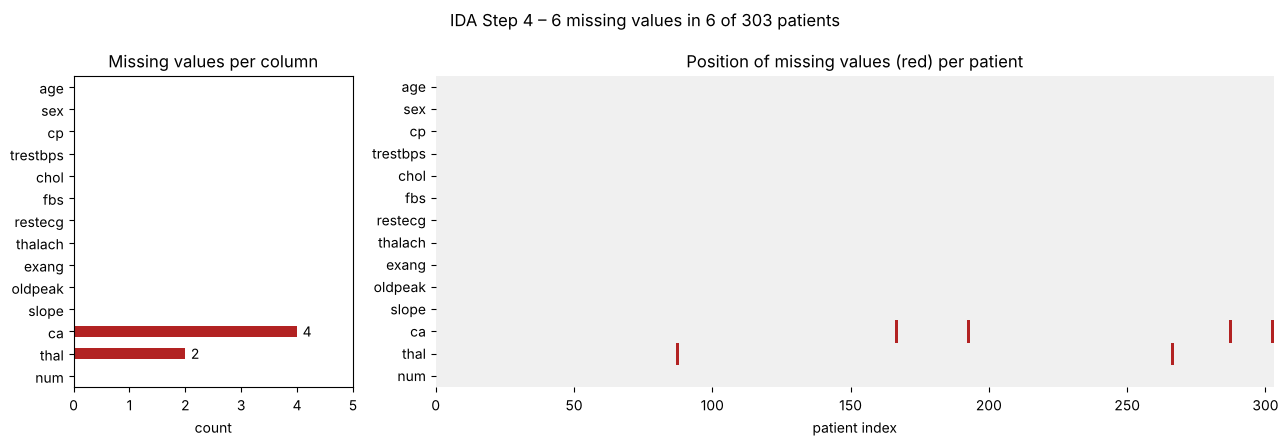

In [7]:
missing = df.isna().sum()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 3]})

# left: number of missing values per column
missing.plot.barh(ax=ax1, color=["firebrick" if m > 0 else "lightgrey" for m in missing])
ax1.invert_yaxis()
ax1.set(title="Missing values per column", xlabel="count", xlim=(0, missing.max() + 1))
for i, m in enumerate(missing):
    if m > 0:
        ax1.text(m + 0.1, i, str(m), va="center")

# right: position of the missing values (red = missing)
sns.heatmap(df.isna().T, cmap=ListedColormap(["#f0f0f0", "firebrick"]), cbar=False, ax=ax2)
ax2.set(title="Position of missing values (red) per patient", xlabel="patient index")
ax2.set_xticks(range(0, len(df), 50))
ax2.set_xticklabels(range(0, len(df), 50), rotation=0)

plt.suptitle(f"IDA Step 4 – {missing.sum()} missing values in "
             f"{df.isna().any(axis=1).sum()} of {len(df)} patients")
plt.tight_layout()
plt.show()

**Observations**

Only 6 values are missing (4 in ca, 2 in thal), each in a different patient, without a pattern. We keep all patients and fill in the missing values later with the most frequent value, inside the model pipeline to avoid data leakage.

**IDA Step 5 – Overview heatmap**

All patients sorted by diagnosis (healthy at the top), all features scaled to [0, 1]. A log transform, as suggested in the lecture, is not needed here because the skewness is only moderate.

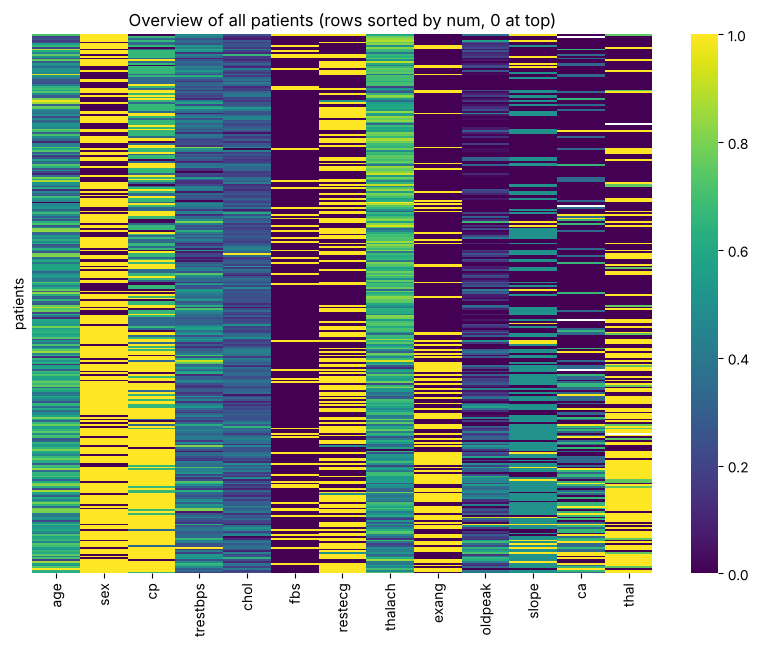

In [8]:
features = [c for c in df.columns if c != "num"]
ordered = df.sort_values("num")                                  # sort patients by diagnosis
scaled = (ordered[features] - ordered[features].min()) / \
         (ordered[features].max() - ordered[features].min())     # min-max scaling to [0, 1]

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(scaled.values, cmap="viridis", xticklabels=features, yticklabels=False, ax=ax)
ax.set(title="Overview of all patients (rows sorted by num, 0 at top)", ylabel="patients")
plt.show()

**Observations**

Patients with heart disease (lower part) more often have cp = 4 and exang = 1, higher oldpeak, ca and thal, and a lower thalach. chol, fbs and trestbps show no visible difference.

**IDA Step 6 – Univariate analysis**

Count plots for the categorical features and the target.

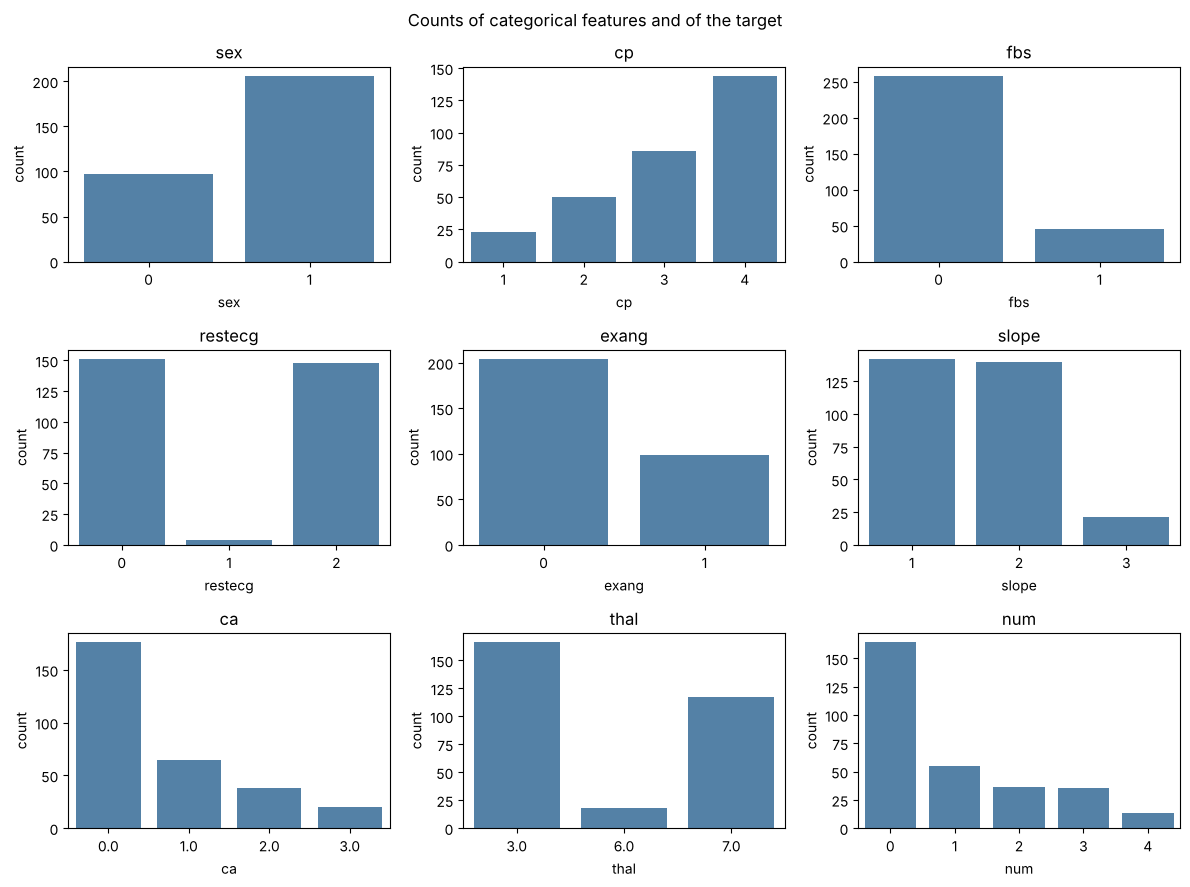

In [9]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal", "num"]
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(x=col, data=df, ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Counts of categorical features and of the target")
plt.tight_layout()
plt.show()

Histograms for the continuous features.

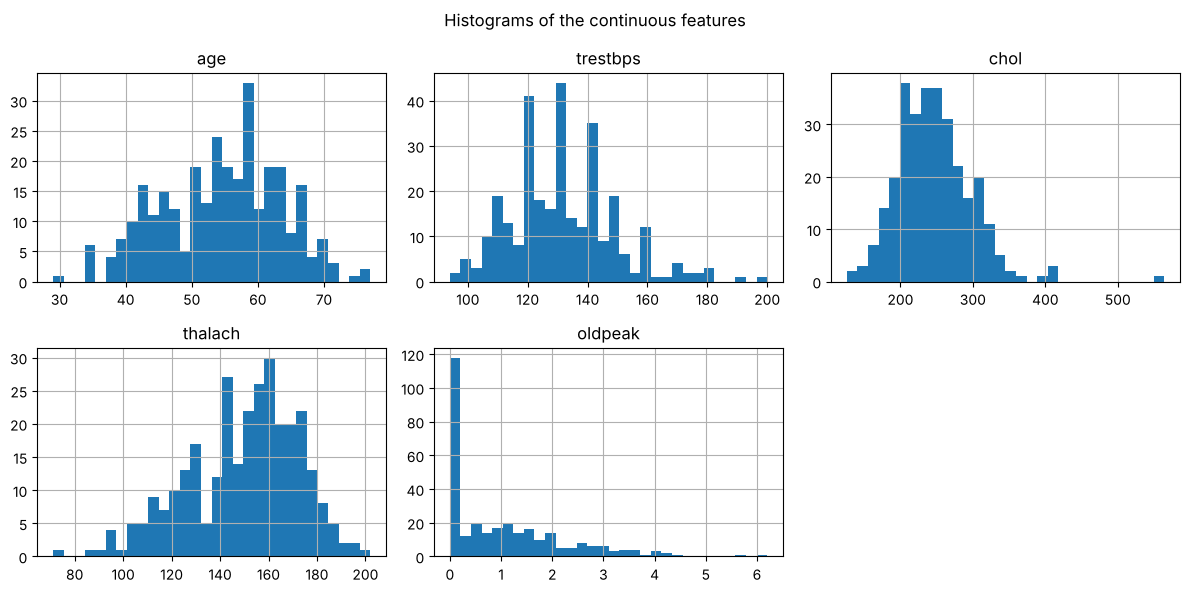

In [10]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
df[num_cols].hist(bins=30, figsize=(12, 6), layout=(2, 3))
plt.suptitle("Histograms of the continuous features")
plt.tight_layout()
plt.show()

Box plots and skewness to find outliers and skewed distributions.

skewness:
 age        -0.21
trestbps    0.71
chol        1.14
thalach    -0.54
oldpeak     1.27
dtype: float64


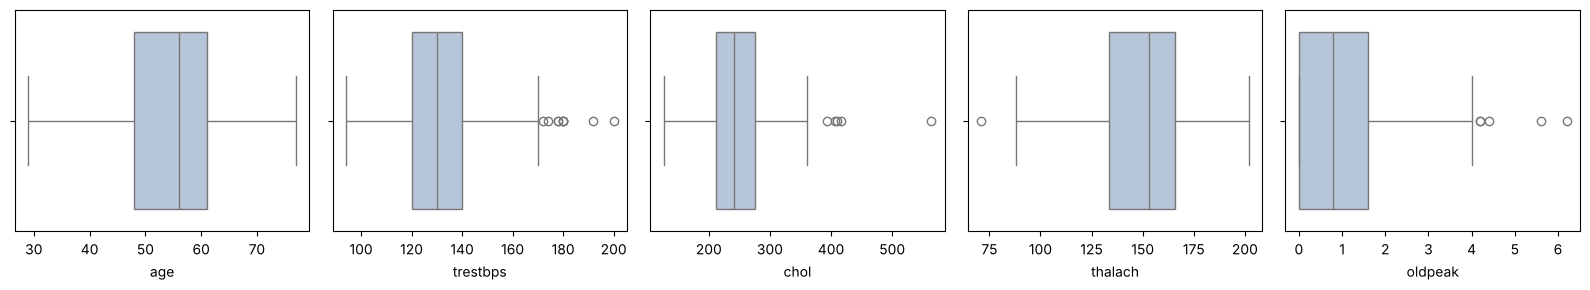

In [11]:
print("skewness:\n", df[num_cols].skew().round(2))
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], ax=ax, color="lightsteelblue")
plt.tight_layout()
plt.show()

**Observations**

There are about twice as many men as women (206 vs. 97). Most patients have cp = 4 (asymptomatic). fbs = 1 is rare (15 %) and restecg = 1 occurs only 4 times. age is roughly symmetric, thalach slightly left-skewed, chol and oldpeak are right-skewed. chol has one extreme value (564) and trestbps some high values (up to 200). These values are medically plausible, so we keep them.

**IDA Step 7 – Relationships between variables**

Pearson and Spearman correlation. We use Spearman for the interpretation because it is robust to outliers and suited for ordinal values.

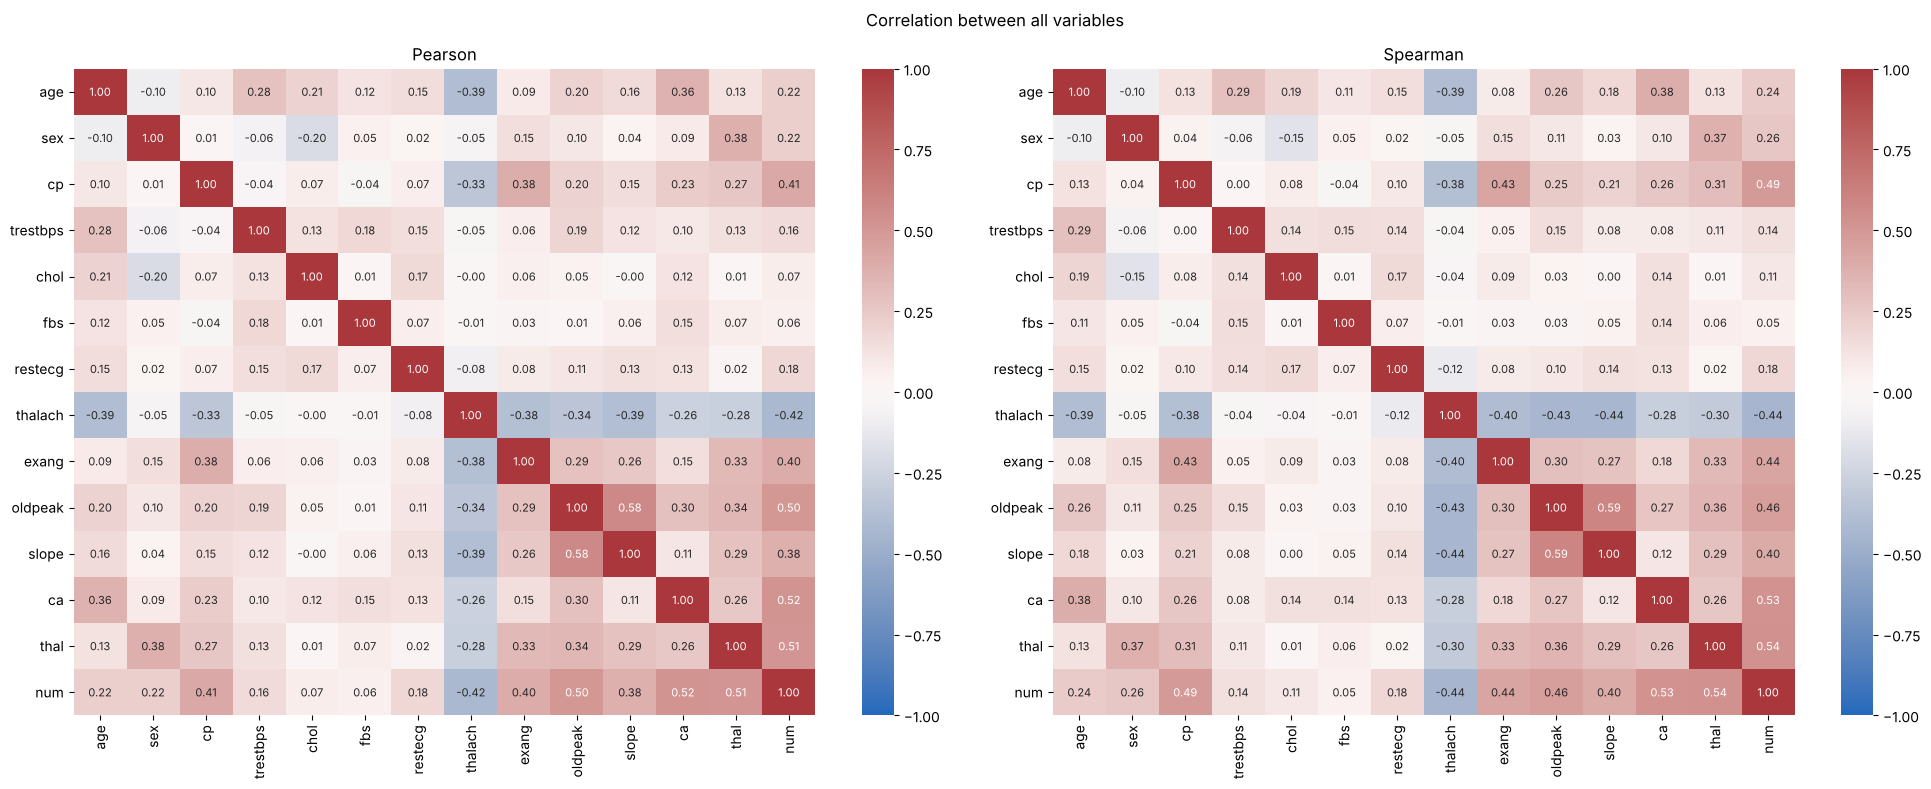

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df.corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                ax=ax, annot_kws={"size": 8})
    ax.set_title(method.capitalize())
plt.suptitle("Correlation between all variables")
plt.tight_layout()
plt.show()

Scatter matrix of the continuous features (black = no disease, yellow = disease).

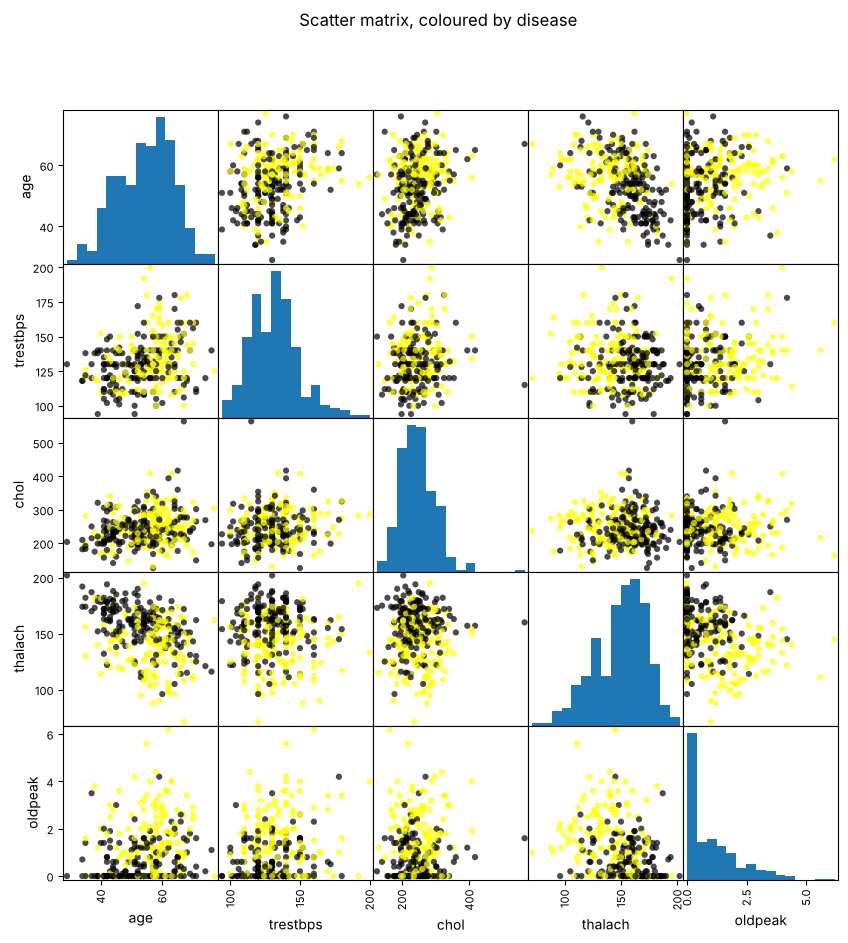

In [13]:
pd.plotting.scatter_matrix(df[num_cols], c=(df["num"] > 0).astype(int), marker="o", s=20,
                           hist_kwds={"bins": 15}, figsize=(10, 10),
                           cmap=plt.get_cmap("gnuplot"), alpha=0.7)
plt.suptitle("Scatter matrix, coloured by disease")
plt.show()

Continuous features per diagnosis class.

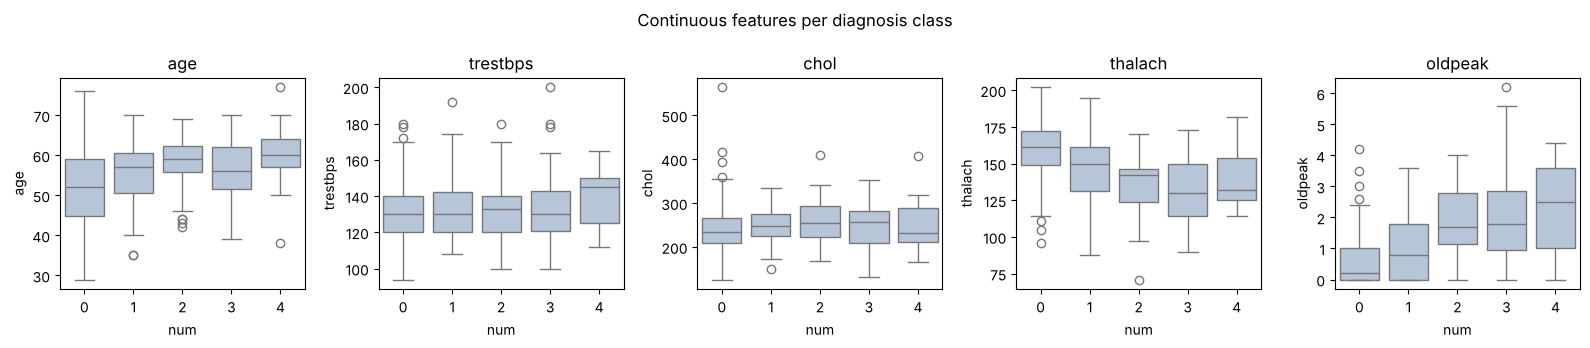

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="num", y=col, data=df, ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.suptitle("Continuous features per diagnosis class")
plt.tight_layout()
plt.show()

**Observations**

Most features are only weakly or moderately correlated with each other. The strongest pair is oldpeak and slope (0.59), so no feature needs to be removed. The features most related to the target are thal (0.54), ca (0.53), cp (0.49), oldpeak (0.46), exang (0.44) and thalach (-0.44). fbs, chol and trestbps are almost unrelated to the diagnosis. In the scatter matrix healthy and diseased patients overlap, so we expect a good but not perfect classifier. The disease classes 1–4 overlap strongly, so predicting the severity will be much harder than predicting disease vs. no disease.